# 07 - Final PA2 Analysis

This notebook integrates the results obtained throughout Practical Application 2.

The analysis includes:

1. Probabilistic classifiers using all original predictors.
2. Univariate filter feature selection.
3. Multivariate filter feature selection.
4. Wrapper feature selection.
5. Representative metaclassifiers.

No new model is trained in this notebook.

The objective is to compare all experimental configurations, identify the
strongest results according to classification and probability-based metrics,
analyse feature-selection behaviour, and generate the final tables and figures
for the scientific report.

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 200)

In [2]:
RESULTS_PATH = Path("../../results/pa2")
FIGURES_PATH = Path("../../figures/pa2")
TABLES_PATH = Path("../../report/tables")

FIGURES_PATH.mkdir(
    parents=True,
    exist_ok=True
)

TABLES_PATH.mkdir(
    parents=True,
    exist_ok=True
)

## 1. Load Experimental Results

The aggregated results generated in the previous PA2 notebooks are loaded.

Each feature-selection experiment contains the results of the same four
probabilistic classifier families:

- Mixed Naive Bayes.
- Logistic Regression.
- LDA.
- QDA.

The metaclassifier experiment contains:

- Bagging.
- AdaBoost.
- Stacking.

In [3]:
baseline = pd.read_csv(
    RESULTS_PATH / "baseline_summary.csv"
)

univariate = pd.read_csv(
    RESULTS_PATH / "univariate_summary.csv"
)

multivariate = pd.read_csv(
    RESULTS_PATH / "multivariate_summary.csv"
)

wrapper = pd.read_csv(
    RESULTS_PATH / "wrapper_summary.csv"
)

metaclassifiers = pd.read_csv(
    RESULTS_PATH / "metaclassifier_summary.csv"
)

print("Baseline:", baseline.shape)
print("Univariate:", univariate.shape)
print("Multivariate:", multivariate.shape)
print("Wrapper:", wrapper.shape)
print("Metaclassifiers:", metaclassifiers.shape)

Baseline: (4, 8)
Univariate: (4, 8)
Multivariate: (4, 8)
Wrapper: (4, 9)
Metaclassifiers: (3, 8)


In [4]:
baseline["Strategy"] = "All Features"
univariate["Strategy"] = "Univariate"
multivariate["Strategy"] = "Multivariate"
wrapper["Strategy"] = "Wrapper"
metaclassifiers["Strategy"] = "Metaclassifier"

common_columns = [
    "Strategy",
    "Model",
    "Accuracy",
    "Precision",
    "Recall",
    "Specificity",
    "F1",
    "AUC",
    "Brier"
]

all_results = pd.concat(
    [
        baseline[common_columns],
        univariate[common_columns],
        multivariate[common_columns],
        wrapper[common_columns],
        metaclassifiers[common_columns]
    ],
    ignore_index=True
)

display(
    all_results.round(4)
)

,Strategy,Model,Accuracy,Precision,Recall,Specificity,F1,AUC,Brier
0,All Features,Logistic Regression,0.8823,0.7344,0.4259,0.9700,0.5373,0.8375,0.1857
1,All Features,Mixed Naive Bayes,0.7986,0.4208,0.6453,0.8281,0.5083,0.7851,0.2902
2,All Features,LDA,0.8639,0.6740,0.3168,0.9692,0.4256,0.8146,0.2036
3,All Features,QDA,0.8150,0.4184,0.3755,0.8994,0.3946,0.7211,0.2786
4,Univariate,Mixed Naive Bayes,0.7707,0.3733,0.6033,0.8029,0.4600,0.7633,0.3190
5,Univariate,QDA,0.8320,0.4728,0.3924,0.9165,0.4240,0.7302,0.2628
6,Univariate,Logistic Regression,0.8578,0.6676,0.2708,0.9708,0.3736,0.7919,0.2112
7,Univariate,LDA,0.8565,0.6328,0.2658,0.9700,0.3700,0.7714,0.2239
8,Multivariate,Mixed Naive Bayes,0.8388,0.5157,0.3531,0.9318,0.3962,0.7616,0.2386
9,Multivariate,QDA,0.8395,0.4934,0.2525,0.9521,0.3259,0.7204,0.2463


## 2. Overall Performance Comparison

The configurations are first ranked according to F1-measure.

F1 is particularly useful in this problem because the positive attrition class
is substantially less frequent than the non-attrition class and the metric
balances Precision and Recall.

In [5]:
f1_ranking = (
    all_results
    .sort_values(
        "F1",
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    f1_ranking[
        [
            "Strategy",
            "Model",
            "F1",
            "Recall",
            "AUC",
            "Brier"
        ]
    ].round(4)
)

,Strategy,Model,F1,Recall,AUC,Brier
0,Metaclassifier,Stacking,0.5394,0.4259,0.8365,0.1846
1,All Features,Logistic Regression,0.5373,0.4259,0.8375,0.1857
2,All Features,Mixed Naive Bayes,0.5083,0.6453,0.7851,0.2902
3,Wrapper,Logistic Regression,0.4696,0.3551,0.8206,0.1976
4,Metaclassifier,AdaBoost,0.4676,0.3380,0.8314,0.3773
5,Univariate,Mixed Naive Bayes,0.4600,0.6033,0.7633,0.3190
6,Wrapper,Mixed Naive Bayes,0.4358,0.4087,0.7701,0.2400
7,All Features,LDA,0.4256,0.3168,0.8146,0.2036
8,Univariate,QDA,0.4240,0.3924,0.7302,0.2628
9,Multivariate,Mixed Naive Bayes,0.3962,0.3531,0.7616,0.2386


## 3. Best Configuration per Strategy

For each experimental strategy, the classifier with the highest mean
F1-measure is identified.

This provides a compact comparison among the four required feature-set analyses
and the additional metaclassifier experiment.

In [6]:
best_per_strategy = (
    all_results
    .loc[
        all_results
        .groupby("Strategy")["F1"]
        .idxmax()
    ]
    .sort_values(
        "F1",
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    best_per_strategy[
        [
            "Strategy",
            "Model",
            "Accuracy",
            "Precision",
            "Recall",
            "Specificity",
            "F1",
            "AUC",
            "Brier"
        ]
    ].round(4)
)

,Strategy,Model,Accuracy,Precision,Recall,Specificity,F1,AUC,Brier
0,Metaclassifier,Stacking,0.8830,0.7472,0.4259,0.9708,0.5394,0.8365,0.1846
1,All Features,Logistic Regression,0.8823,0.7344,0.4259,0.9700,0.5373,0.8375,0.1857
2,Wrapper,Logistic Regression,0.8714,0.7287,0.3551,0.9708,0.4696,0.8206,0.1976
3,Univariate,Mixed Naive Bayes,0.7707,0.3733,0.6033,0.8029,0.4600,0.7633,0.3190
4,Multivariate,Mixed Naive Bayes,0.8388,0.5157,0.3531,0.9318,0.3962,0.7616,0.2386


## 4. Best Configuration by Evaluation Metric

Different metrics emphasize different aspects of classifier performance.

The best configuration is therefore identified independently for:

- F1-measure.
- Recall.
- AUC.
- Brier score.

For F1, Recall, and AUC, higher values are better.

For Brier score, lower values are better.

In [7]:
best_f1 = all_results.loc[
    all_results["F1"].idxmax()
]

best_recall = all_results.loc[
    all_results["Recall"].idxmax()
]

best_auc = all_results.loc[
    all_results["AUC"].idxmax()
]

best_brier = all_results.loc[
    all_results["Brier"].idxmin()
]

best_metrics = pd.DataFrame([
    {
        "Metric": "F1",
        "Strategy": best_f1["Strategy"],
        "Model": best_f1["Model"],
        "Value": best_f1["F1"]
    },
    {
        "Metric": "Recall",
        "Strategy": best_recall["Strategy"],
        "Model": best_recall["Model"],
        "Value": best_recall["Recall"]
    },
    {
        "Metric": "AUC",
        "Strategy": best_auc["Strategy"],
        "Model": best_auc["Model"],
        "Value": best_auc["AUC"]
    },
    {
        "Metric": "Brier",
        "Strategy": best_brier["Strategy"],
        "Model": best_brier["Model"],
        "Value": best_brier["Brier"]
    }
])

display(
    best_metrics.round(4)
)

,Metric,Strategy,Model,Value
0,F1,Metaclassifier,Stacking,0.5394
1,Recall,All Features,Mixed Naive Bayes,0.6453
2,AUC,All Features,Logistic Regression,0.8375
3,Brier,Metaclassifier,Stacking,0.1846


## 5. F1 Comparison

F1-measure is visualized across all probabilistic classifiers and feature-set
strategies.

The metaclassifiers are included as an additional strategy.

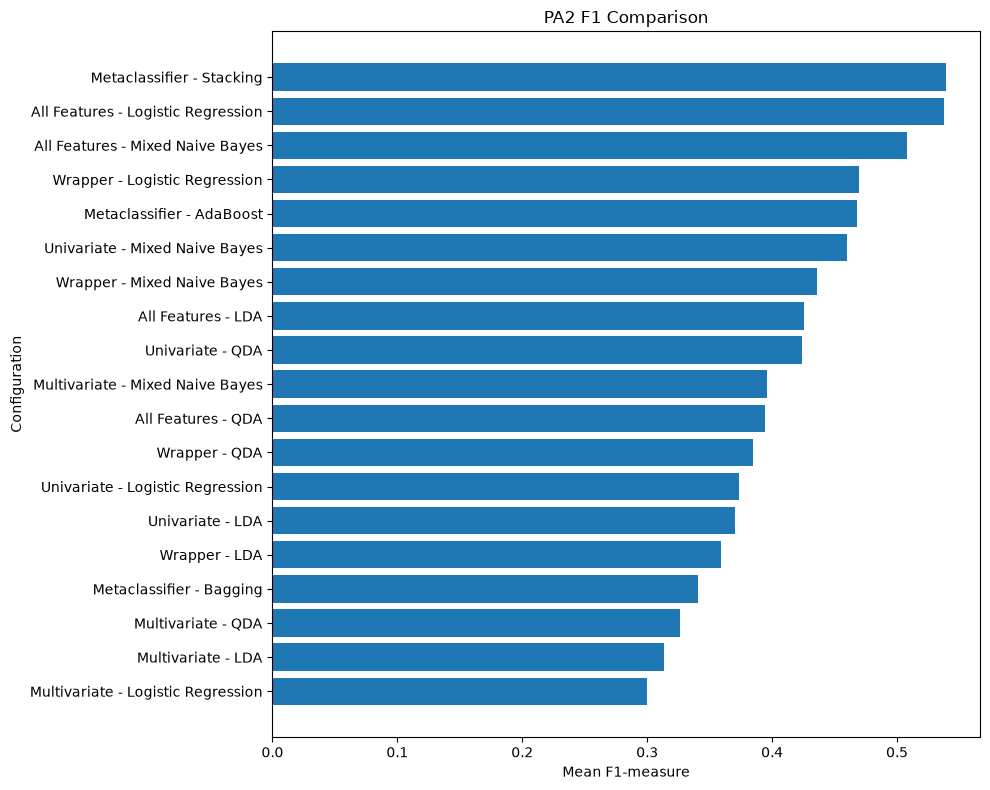

In [8]:
plot_data = (
    all_results
    .sort_values(
        "F1",
        ascending=True
    )
    .copy()
)

labels = (
    plot_data["Strategy"]
    + " - "
    + plot_data["Model"]
)

fig, ax = plt.subplots(
    figsize=(10, 8)
)

ax.barh(
    labels,
    plot_data["F1"]
)

ax.set_xlabel(
    "Mean F1-measure"
)

ax.set_ylabel(
    "Configuration"
)

ax.set_title(
    "PA2 F1 Comparison"
)

plt.tight_layout()

plt.savefig(
    FIGURES_PATH / "f1_comparison.pdf",
    bbox_inches="tight"
)

plt.show()

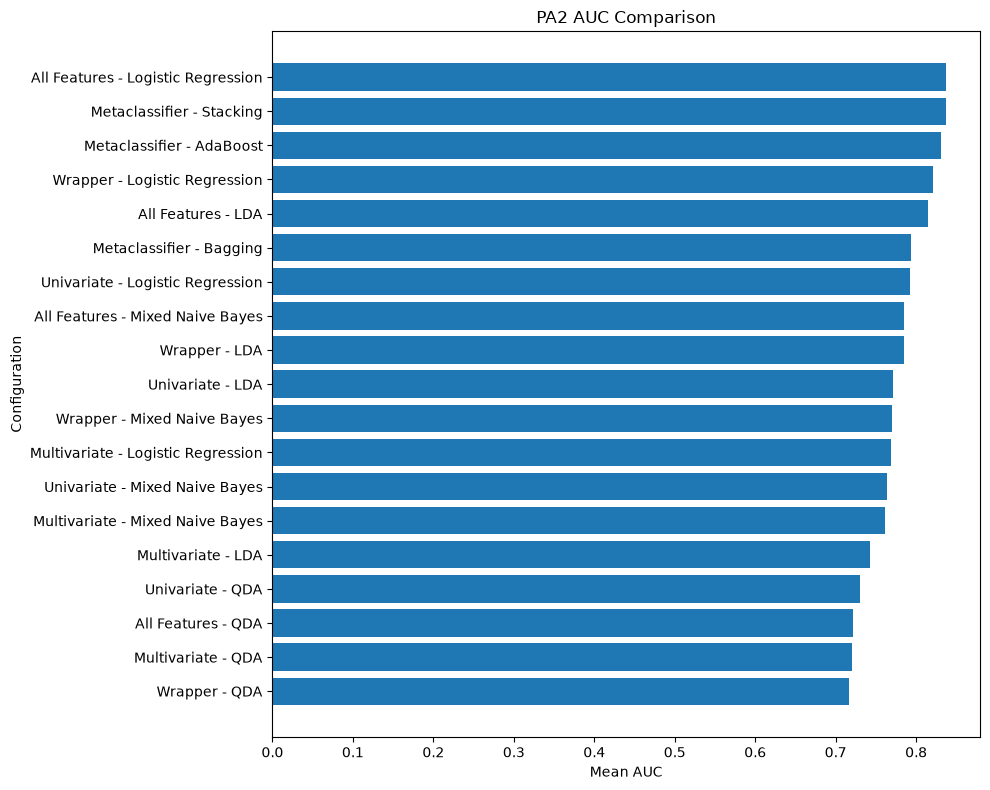

In [9]:
plot_data = (
    all_results
    .sort_values(
        "AUC",
        ascending=True
    )
    .copy()
)

labels = (
    plot_data["Strategy"]
    + " - "
    + plot_data["Model"]
)

fig, ax = plt.subplots(
    figsize=(10, 8)
)

ax.barh(
    labels,
    plot_data["AUC"]
)

ax.set_xlabel(
    "Mean AUC"
)

ax.set_ylabel(
    "Configuration"
)

ax.set_title(
    "PA2 AUC Comparison"
)

plt.tight_layout()

plt.savefig(
    FIGURES_PATH / "auc_comparison.pdf",
    bbox_inches="tight"
)

plt.show()

## 6. Probability Quality

The Brier score evaluates the quality of the complete predicted probability
vector.

Unlike F1 and AUC, lower Brier scores represent better performance.

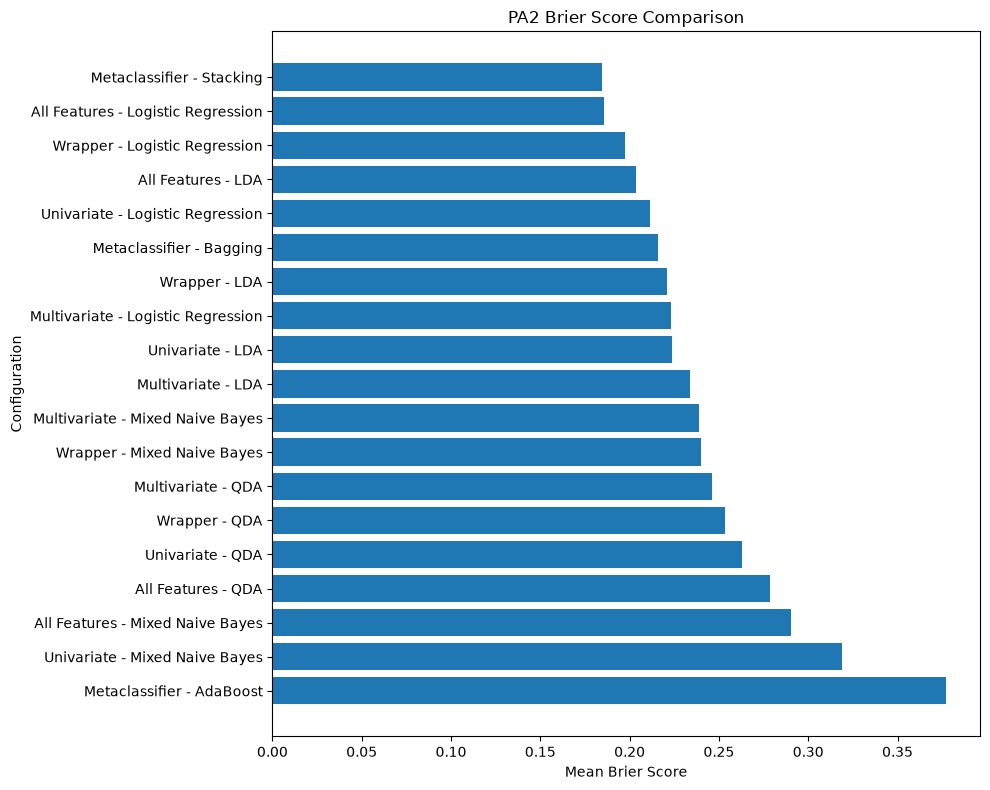

In [10]:
plot_data = (
    all_results
    .sort_values(
        "Brier",
        ascending=False
    )
    .copy()
)

labels = (
    plot_data["Strategy"]
    + " - "
    + plot_data["Model"]
)

fig, ax = plt.subplots(
    figsize=(10, 8)
)

ax.barh(
    labels,
    plot_data["Brier"]
)

ax.set_xlabel(
    "Mean Brier Score"
)

ax.set_ylabel(
    "Configuration"
)

ax.set_title(
    "PA2 Brier Score Comparison"
)

plt.tight_layout()

plt.savefig(
    FIGURES_PATH / "brier_comparison.pdf",
    bbox_inches="tight"
)

plt.show()

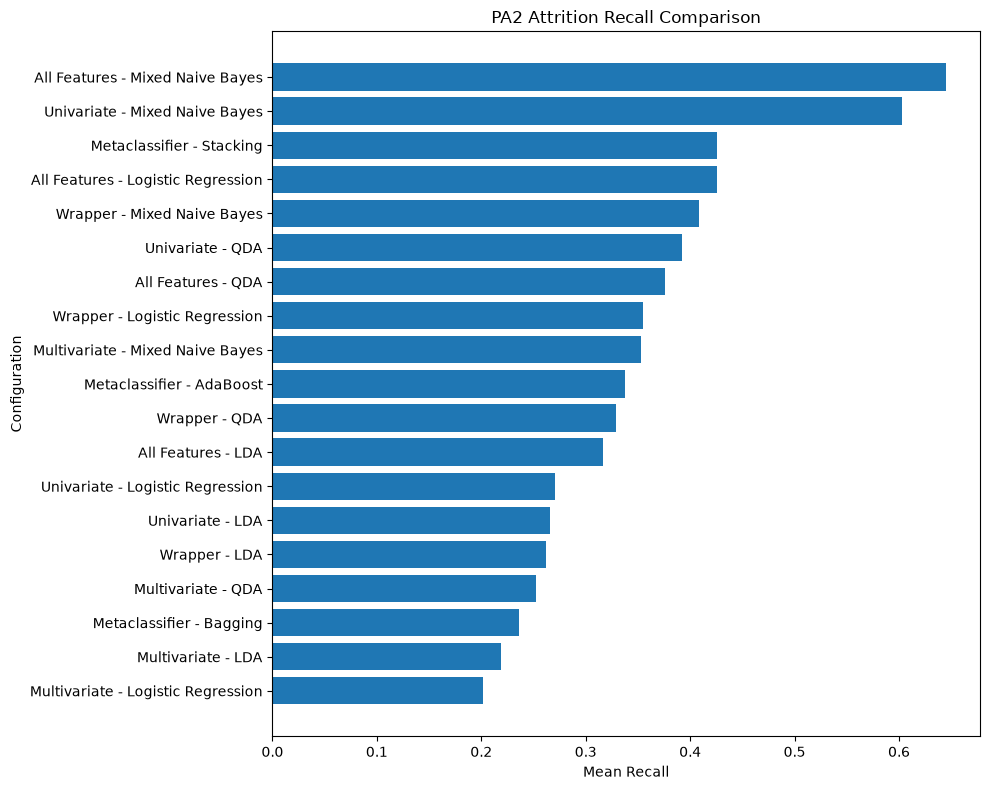

In [11]:
plot_data = (
    all_results
    .sort_values(
        "Recall",
        ascending=True
    )
    .copy()
)

labels = (
    plot_data["Strategy"]
    + " - "
    + plot_data["Model"]
)

fig, ax = plt.subplots(
    figsize=(10, 8)
)

ax.barh(
    labels,
    plot_data["Recall"]
)

ax.set_xlabel(
    "Mean Recall"
)

ax.set_ylabel(
    "Configuration"
)

ax.set_title(
    "PA2 Attrition Recall Comparison"
)

plt.tight_layout()

plt.savefig(
    FIGURES_PATH / "recall_comparison.pdf",
    bbox_inches="tight"
)

plt.show()

## 7. Feature-Selection Behaviour

The three feature-selection strategies differ substantially in the number of
original predictors retained.

- The univariate filter retains exactly 15 predictors.
- CFS determines the best subset according to its multivariate merit.
- The wrapper determines a different subset for each classifier.

The following analysis summarizes the dimensionality reduction achieved by
each method.

In [12]:
multivariate_subsets = pd.read_csv(
    RESULTS_PATH / "multivariate_selected_subsets.csv"
)

wrapper_subsets = pd.read_csv(
    RESULTS_PATH / "wrapper_selected_subsets.csv"
)

print("Univariate selected predictors: 15 / 30")

print(
    "\nMultivariate CFS:"
)

print(
    multivariate_subsets[
        "NumberSelected"
    ].describe()
)

print(
    "\nWrapper mean selected predictors by model:"
)

display(
    wrapper_subsets
    .groupby("Model")[
        "NumberSelected"
    ]
    .agg([
        "mean",
        "min",
        "max"
    ])
    .round(2)
)

Univariate selected predictors: 15 / 30

Multivariate CFS:
count    10.000000
mean      7.800000
std       2.936362
min       3.000000
25%       5.250000
50%       9.000000
75%       9.750000
max      11.000000
Name: NumberSelected, dtype: float64

Wrapper mean selected predictors by model:


,mean,min,max
Model,,,
LDA,13.5,11,15
Logistic Regression,14.6,13,15
Mixed Naive Bayes,13.1,10,15
QDA,12.9,9,15


## 8. Feature-Selection Stability

Selection frequency provides information about how consistently a predictor is
retained across cross-validation folds.

The most stable variables from the univariate and multivariate filters are
examined below.

In [13]:
univariate_frequency = pd.read_csv(
    RESULTS_PATH / "univariate_selection_frequency.csv"
)

multivariate_frequency = pd.read_csv(
    RESULTS_PATH / "multivariate_selection_frequency.csv"
)

print("Most stable univariate variables:")

display(
    univariate_frequency
    .head(15)
)

print("\nMost stable multivariate variables:")

display(
    multivariate_frequency
    .head(15)
)

Most stable univariate variables:


,Feature,SelectedFolds
0,Age,10
1,BusinessTravel,10
2,JobInvolvement,10
3,JobLevel,10
4,JobRole,10
5,MaritalStatus,10
6,MonthlyIncome,10
7,OverTime,10
8,StockOptionLevel,10
9,TotalWorkingYears,10



Most stable multivariate variables:


,Feature,SelectedFolds
0,JobLevel,10
1,OverTime,10
2,StockOptionLevel,10
3,YearsAtCompany,9
4,Age,7
5,BusinessTravel,7
6,JobRole,7
7,MaritalStatus,7
8,JobInvolvement,6
9,YearsWithCurrManager,4


In [14]:
stable_univariate = set(
    univariate_frequency.loc[
        univariate_frequency[
            "SelectedFolds"
        ] >= 8,
        "Feature"
    ]
)

stable_multivariate = set(
    multivariate_frequency.loc[
        multivariate_frequency[
            "SelectedFolds"
        ] >= 8,
        "Feature"
    ]
)

common_stable_features = sorted(
    stable_univariate
    & stable_multivariate
)

print(
    "Variables selected in at least 8 folds "
    "by both filter strategies:"
)

print(
    common_stable_features
)

Variables selected in at least 8 folds by both filter strategies:
['JobLevel', 'OverTime', 'StockOptionLevel', 'YearsAtCompany']


## 9. Best Reduced-Feature Configuration

Only the three feature-selection experiments are considered here.

This identifies the strongest classifier obtained after dimensionality
reduction, independently of the complete-feature and metaclassifier results.

In [15]:
reduced_results = all_results[
    all_results["Strategy"].isin(
        [
            "Univariate",
            "Multivariate",
            "Wrapper"
        ]
    )
].copy()

best_reduced = reduced_results.loc[
    reduced_results["F1"].idxmax()
]

display(
    best_reduced[
        [
            "Strategy",
            "Model",
            "Accuracy",
            "Precision",
            "Recall",
            "Specificity",
            "F1",
            "AUC",
            "Brier"
        ]
    ]
    .to_frame()
    .T
)

,Strategy,Model,Accuracy,Precision,Recall,Specificity,F1,AUC,Brier
12,Wrapper,Logistic Regression,0.871429,0.728738,0.355072,0.97081,0.469596,0.820569,0.197556


## 10. Main Configuration Comparison

The most relevant configurations are compared directly:

- Best complete-feature probabilistic classifier.
- Best univariate-filter classifier.
- Best multivariate-filter classifier.
- Best wrapper classifier.
- Best metaclassifier.

In [16]:
main_comparison = (
    best_per_strategy[
        [
            "Strategy",
            "Model",
            "Accuracy",
            "Precision",
            "Recall",
            "Specificity",
            "F1",
            "AUC",
            "Brier"
        ]
    ]
    .copy()
)

display(
    main_comparison.round(4)
)

,Strategy,Model,Accuracy,Precision,Recall,Specificity,F1,AUC,Brier
0,Metaclassifier,Stacking,0.8830,0.7472,0.4259,0.9708,0.5394,0.8365,0.1846
1,All Features,Logistic Regression,0.8823,0.7344,0.4259,0.9700,0.5373,0.8375,0.1857
2,Wrapper,Logistic Regression,0.8714,0.7287,0.3551,0.9708,0.4696,0.8206,0.1976
3,Univariate,Mixed Naive Bayes,0.7707,0.3733,0.6033,0.8029,0.4600,0.7633,0.3190
4,Multivariate,Mixed Naive Bayes,0.8388,0.5157,0.3531,0.9318,0.3962,0.7616,0.2386


## 11. Export Final Analysis Tables

The final comparison tables are exported for later use in the scientific
report.

In [17]:
all_results.to_csv(
    RESULTS_PATH / "final_all_results.csv",
    index=False
)

best_per_strategy.to_csv(
    RESULTS_PATH / "final_best_per_strategy.csv",
    index=False
)

best_metrics.to_csv(
    RESULTS_PATH / "final_best_metrics.csv",
    index=False
)

main_comparison.to_csv(
    RESULTS_PATH / "final_main_comparison.csv",
    index=False
)

print(
    "Final PA2 CSV results saved successfully."
)

Final PA2 CSV results saved successfully.


In [18]:
report_table = (
    main_comparison[
        [
            "Strategy",
            "Model",
            "Recall",
            "F1",
            "AUC",
            "Brier"
        ]
    ]
    .copy()
)

report_table[
    [
        "Recall",
        "F1",
        "AUC",
        "Brier"
    ]
] = (
    report_table[
        [
            "Recall",
            "F1",
            "AUC",
            "Brier"
        ]
    ]
    .round(4)
)

latex_table = report_table.to_latex(
    index=False,
    escape=True
)

with open(
    TABLES_PATH / "pa2_best_per_strategy.tex",
    "w",
    encoding="utf-8"
) as file:

    file.write(
        latex_table
    )

print(
    "LaTeX table saved:"
)

print(
    TABLES_PATH / "pa2_best_per_strategy.tex"
)

LaTeX table saved:
..\..\report\tables\pa2_best_per_strategy.tex


In [19]:
best_metrics_report = (
    best_metrics.copy()
)

best_metrics_report[
    "Value"
] = (
    best_metrics_report[
        "Value"
    ]
    .round(4)
)

latex_table = (
    best_metrics_report
    .to_latex(
        index=False,
        escape=True
    )
)

with open(
    TABLES_PATH / "pa2_best_metrics.tex",
    "w",
    encoding="utf-8"
) as file:

    file.write(
        latex_table
    )

print(
    "Best-metric LaTeX table saved."
)

Best-metric LaTeX table saved.


## 12. Final Main Observations

The complete PA2 comparison shows that the strongest predictive configurations
are obtained without feature selection.

Stacking achieves the highest overall F1-measure (0.5394) and the lowest Brier
score (0.1846). However, the improvement over the full-feature Logistic
Regression baseline is very small. Logistic Regression obtains F1 = 0.5373,
the highest AUC of all configurations (0.8375), and a Brier score of 0.1857.

Mixed Naive Bayes using all predictors provides the highest Recall (0.6453).
This means that it identifies the largest proportion of employees belonging to
the attrition class, although this increased sensitivity is accompanied by
lower Precision and poorer probability quality than Logistic Regression or
Stacking.

None of the three feature-selection strategies improves the strongest
full-feature configuration in terms of F1 or AUC.

Among reduced-feature configurations, Wrapper Logistic Regression provides the
highest F1-measure (0.4696). The univariate filter performs best with Mixed
Naive Bayes (F1 = 0.4600), whereas the multivariate CFS strategy produces its
best result with Mixed Naive Bayes (F1 = 0.3962).

The dimensionality reduction achieved by the three selection strategies is
different. The univariate filter always retains 15 of the 30 original
predictors. CFS selects considerably smaller subsets, with an average of 7.8
variables and between 3 and 11 variables across folds. The wrapper retains
larger classifier-specific subsets, with approximately 13 to 15 variables on
average.

Feature-selection stability also provides useful interpretative information.
Four predictors are selected in at least eight folds by both the univariate
and multivariate filters: `JobLevel`, `OverTime`, `StockOptionLevel`, and
`YearsAtCompany`. These variables therefore appear particularly robust across
different filter-selection criteria.

Overall, reducing dimensionality is not necessary to obtain the strongest
predictive performance for this dataset. Stacking provides the best F1 and
Brier score, while the simpler full-feature Logistic Regression remains highly
competitive and obtains the best AUC. Mixed Naive Bayes with all predictors
remains the most sensitive configuration according to Recall.

## 13. PA2 Summary

The four analyses required for probabilistic supervised classification have
been completed:

1. All original valid predictors.
2. Univariate filter feature selection.
3. Multivariate filter feature selection.
4. Wrapper feature selection.

Representative metaclassifiers have also been evaluated.

All predictive performance estimates were obtained using stratified
cross-validation, with feature selection and preprocessing performed only from
training data.

The final results and figures generated in this notebook will be used in the
integrated PA1-PA2 scientific report.